In [3]:
# 4.4 Stochastic model for daily cargo throughput
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

file_rotterdamPortData = r'..\data\rotterdam_dataset_16.xlsx'
wd = pd.read_excel(file_rotterdamPortData)
wd['Day'] = wd['Arrival_Date'].dt.normalize()


types = ['Container', 'Tanker', 'Bulk']
# includes days without arrivals
allDays = pd.date_range(wd['Day'].min(), wd['Day'].max())   
T_data = len(allDays)
print('number of observed days:', T_data)

number of observed days: 1096


In [4]:
# Model (see report, Section 3):
#   N_i(t) ~ Poisson process with rate lambda_i, i = Container, Tanker, Bulk
#   X_i,k  ~ iid lognormal(mu_i, sigma_i^2), cargo of the k-th type-i vessel
#   S_i(t) = X_i,1 + ... + X_i,N_i(t)   (Compound Poisson Process)
#   N(t) = sum of N_i(t),  S(t) = sum of S_i(t)

In [5]:
# Method of moments
# lambda_i = arrivals / days
# lognormal: sigma^2 = log(1 + s^2/m^2), mu = log(m) - sigma^2/2
lam = {}
mu = {}
sigma = {}
rows = []


for t in types:
    x = wd.loc[wd['Vessel_Type'] == t, 'Cargo_tons'].values
    lam[t] = len(x) / T_data
    m = np.mean(x)
    s2 = np.var(x)
    sigma2 = np.log(1 + s2 / m**2)
    mu[t] = np.log(m) - sigma2 / 2
    sigma[t] = np.sqrt(sigma2)
    rows.append([t, len(x), lam[t], mu[t], sigma[t], m, np.sqrt(s2)])

param_table = pd.DataFrame(rows, columns=['Type', 'Arrivals', 'lambda (per day)', 'mu', 'sigma','sample mean cargo', 'sample std cargo'])
print(param_table.round(4).to_string(index=False))

     Type  Arrivals  lambda (per day)      mu  sigma  sample mean cargo  sample std cargo
Container      6117            5.5812  9.6069 0.3493         15801.2297         5691.4063
   Tanker      2444            2.2299 10.9119 0.2963         57284.2009        17355.0881
     Bulk      2515            2.2947 10.4989 0.3806         39001.6386        15396.0237


In [6]:
# check: fitted lognormal reproduces sample mean and std

for t in types:
    cargoDist = stats.lognorm(s=sigma[t], scale=np.exp(mu[t]))
    print(t, '- model mean:', round(cargoDist.mean()), ' model std:', round(cargoDist.std()))

Container - model mean: 15801  model std: 5691
Tanker - model mean: 57284  model std: 17355
Bulk - model mean: 39002  model std: 15396


In [7]:
# Observed daily counts and daily throughput
dailyN = pd.DataFrame({t: wd[wd['Vessel_Type'] == t].groupby('Day').size().reindex(allDays, fill_value=0) for t in types})
dailyN['All'] = dailyN[types].sum(axis=1)
dailyS = wd.groupby('Day')['Cargo_tons'].sum().reindex(allDays, fill_value=0)

print(dailyN.describe().round(2))
print('\nobserved daily throughput: mean =', round(dailyS.mean()), ' std =', round(dailyS.std()),' max =', round(dailyS.max()))
print('days above 650,000 tons:', np.sum(dailyS > 650000), 'of', T_data)

       Container   Tanker     Bulk      All
count    1096.00  1096.00  1096.00  1096.00
mean        5.58     2.23     2.29    10.11
std         2.41     1.52     1.52     3.27
min         0.00     0.00     0.00     2.00
25%         4.00     1.00     1.00     8.00
50%         5.00     2.00     2.00    10.00
75%         7.00     3.00     3.00    12.00
max        15.00     9.00     8.00    22.00

observed daily throughput: mean = 305427  std = 118631  max = 764676
days above 650,000 tons: 10 of 1096


In [8]:
# A1: Poisson counts: var/mean close to 1

for t in types + ['All']:
    print(t, '- mean:', round(dailyN[t].mean(), 3), ' var:', round(dailyN[t].var(), 3),' var/mean:', round(dailyN[t].var() / dailyN[t].mean(), 3))

Container - mean: 5.581  var: 5.824  var/mean: 1.043
Tanker - mean: 2.23  var: 2.303  var/mean: 1.033
Bulk - mean: 2.295  var: 2.319  var/mean: 1.011
All - mean: 10.106  var: 10.697  var/mean: 1.059


In [9]:
# A2: independence between types: daily counts uncorrelated
pairs = [('Container', 'Tanker'), ('Container', 'Bulk'), ('Tanker', 'Bulk')]

for a, b in pairs:
    r, p = stats.pearsonr(dailyN[a], dailyN[b])
    print(a, '-', b, ': correlation =', round(r, 3), ' p-value =', round(p, 3))

Container - Tanker : correlation = -0.008  p-value = 0.795
Container - Bulk : correlation = 0.015  p-value = 0.615
Tanker - Bulk : correlation = 0.043  p-value = 0.159


In [10]:
# A3/A4: cargo independent of arrivals
# month effect (Kruskal-Wallis) and correlation between daily count and mean cargo that day


for t in types:
    sub = wd[wd['Vessel_Type'] == t]
    groups = [g['Cargo_tons'].values for month, g in sub.groupby(sub['Arrival_Date'].dt.month)]
    p_month = stats.kruskal(*groups).pvalue
    countPerDay = sub.groupby('Day').size()
    meanCargoPerDay = sub.groupby('Day')['Cargo_tons'].mean()
    r, p_corr = stats.pearsonr(countPerDay, meanCargoPerDay)
    print(t, ': month effect p =', round(p_month, 3), ' | corr(count, mean cargo) =', round(r, 3),' p =', round(p_corr, 3))

Container : month effect p = 0.616  | corr(count, mean cargo) = -0.011  p = 0.726
Tanker : month effect p = 0.999  | corr(count, mean cargo) = 0.001  p = 0.968
Bulk : month effect p = 0.228  | corr(count, mean cargo) = -0.01  p = 0.744


In [11]:
# Candidate models: A = basic, B = monthly rates, C = gamma for bulk
# daily mean and std from E[S] = sum of lambda_i E[X_i], Var[S] = sum of lambda_i E[X_i^2]
def EX2(dist):
    return dist.var() + dist.mean()**2


lognormDist = {t: stats.lognorm(s=sigma[t], scale=np.exp(mu[t])) for t in types}
xBulk = wd.loc[wd['Vessel_Type'] == 'Bulk', 'Cargo_tons'].values
a, loc, scale = stats.gamma.fit(xBulk, floc=0)
gammaBulk = stats.gamma(a, loc=0, scale=scale)


# Model A
meanA = sum(lam[t] * lognormDist[t].mean() for t in types)
stdA = np.sqrt(sum(lam[t] * EX2(lognormDist[t]) for t in types))

# Model C
cargoC = {'Container': lognormDist['Container'], 'Tanker': lognormDist['Tanker'], 'Bulk': gammaBulk}
meanC = sum(lam[t] * cargoC[t].mean() for t in types)
stdC = np.sqrt(sum(lam[t] * EX2(cargoC[t]) for t in types))

# Model B: mixture over days, Var = mean of daily variances + variance of daily means
daysPerMonth = pd.Series(allDays.month).value_counts().sort_index()
lamMonth = {t: wd[wd['Vessel_Type'] == t].groupby(wd['Day'].dt.month).size() / daysPerMonth for t in types}
months = allDays.month
m_d = np.array([sum(lamMonth[t][mo] * lognormDist[t].mean() for t in types) for mo in months])
v_d = np.array([sum(lamMonth[t][mo] * EX2(lognormDist[t]) for t in types) for mo in months])
meanB = np.mean(m_d)
stdB = np.sqrt(np.mean(v_d) + np.var(m_d))

comparison = pd.DataFrame({'Mean daily throughput': [dailyS.mean(), meanA, meanB, meanC],
                           'Std daily throughput': [dailyS.std(), stdA, stdB, stdC]},
                          index=['Data', 'Model A (basic)', 'Model B (seasonal)', 'Model C (gamma bulk)'])
print(comparison.round(0))

                      Mean daily throughput  Std daily throughput
Data                               305427.0              118631.0
Model A (basic)                    305427.0              116610.0
Model B (seasonal)                 305427.0              122398.0
Model C (gamma bulk)               305427.0              116605.0


     Container  Tanker  Bulk
Day                         
1         4.49    2.03  2.03
2         4.85    1.95  2.08
3         5.48    2.23  2.30
4         5.12    2.16  2.07
5         6.42    2.47  2.90
6         6.27    2.91  2.52
7         6.88    2.55  2.48
8         6.65    2.28  2.58
9         5.29    2.03  2.16
10        5.52    2.13  2.40
11        5.19    2.23  2.24
12        4.74    1.77  1.74


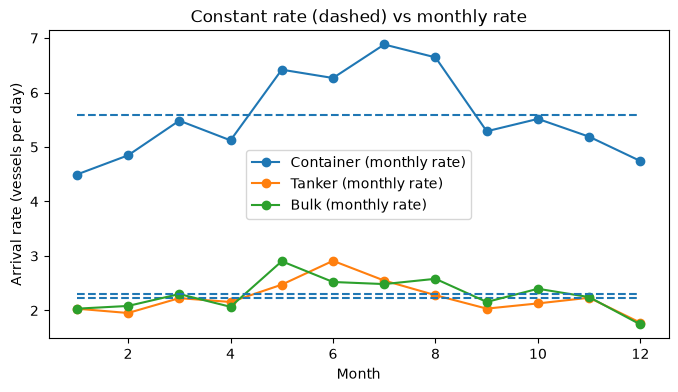

In [12]:
# monthly rates (model B) vs constant rate (model A)
print(pd.DataFrame(lamMonth).round(2))


plt.figure(figsize=(8, 4))
for t in types:
    plt.plot(lamMonth[t].index, lamMonth[t].values, marker='o', label=t + ' (monthly rate)')
    plt.hlines(lam[t], 1, 12, linestyles='dashed')
plt.xlabel('Month')
plt.ylabel('Arrival rate (vessels per day)')
plt.title('Constant rate (dashed) vs monthly rate')
plt.legend()
plt.show()